<a href="https://colab.research.google.com/github/radevicstefan-afk/dsb_capstone/blob/main/Kindle%20EDA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


In [9]:
df = pd.read_csv('/content/kindle_data-v2.csv')
df.head

<bound method NDFrame.head of               asin                                              title  \
0       B00TZE87S4  Adult Children of Emotionally Immature Parents...   
1       B08WCKY8MB  From Strength to Strength: Finding Success, Ha...   
2       B09KPS84CJ  Good Inside: A Guide to Becoming the Parent Yo...   
3       B07S7QPG6J             Everything I Know About Love: A Memoir   
4       B00N6PEQV0  The Seven Principles for Making Marriage Work:...   
...            ...                                                ...   
133097  B0C3SJDLK8                                      Anna Karenina   
133098  B09DW752Y1  Scary Smart: Scary Smart: The Future of Artifi...   
133099  B0CFWHPJTN  The Count of Monte Cristo: The Original Unabri...   
133100  B0C1KMFXJC                                      War And Peace   
133101  B0BS1KYZB6                                Pride and Prejudice   

                   author                    soldBy  \
0       Lindsay C. Gibson   Amazon.com Services LLC   
1        Arthur C. Brooks   Penguin Group (USA) LLC   
2           Becky Kennedy  HarperCollins Publishers   
3          Dolly Alderton  HarperCollins Publishers   
4            John Gottman          Random House LLC   
...                   ...                       ...   
133097        Leo Tolstoy                 De Marque   
133098          Mo Gawdat   Amazon.com Services LLC   
133099    Alexandre Dumas                 De Marque   
133100        Leo Tolstoy                 De Marque   
133101        Jane Austen                 De Marque   

                                                   imgUrl  \
0       https://m.media-amazon.com/images/I/713KZTsaYp...   
1       https://m.media-amazon.com/images/I/A1LZcJFs9E...   
2       https://m.media-amazon.com/images/I/71RIWM0sv6...   
3       https://m.media-amazon.com/images/I/71QdQpTiKZ...   
4       https://m.media-amazon.com/images/I/813o4WOs+w...   
...                                                   ...   
133097  https://m.media-amazon.com/images/I/61RXEyMctk...   
133098  https://m.media-amazon.com/images/I/71tjf6R-Wa...   
133099  https://m.media-amazon.com/images/I/71zcCb5Pvu...   
133100  https://m.media-amazon.com/images/I/715QpZlzmi...   
133101  https://m.media-amazon.com/images/I/81Scutrtj4...   

                                  productURL  stars  reviews  price  \
0       https://www.amazon.com/dp/B00TZE87S4    4.8        0   9.99   
1       https://www.amazon.com/dp/B08WCKY8MB    4.4        0  16.99   
2       https://www.amazon.com/dp/B09KPS84CJ    4.8        0  16.99   
3       https://www.amazon.com/dp/B07S7QPG6J    4.2        0   9.95   
4       https://www.amazon.com/dp/B00N6PEQV0    4.7        0  13.99   
...                                      ...    ...      ...    ...   
133097  https://www.amazon.com/dp/B0C3SJDLK8    4.7        0   0.00   
133098  https://www.amazon.com/dp/B09DW752Y1    4.4        0   9.99   
133099  https://www.amazon.com/dp/B0CFWHPJTN    4.8        0   1.99   
133100  https://www.amazon.com/dp/B0C1KMFXJC    4.7        0   0.00   
133101  https://www.amazon.com/dp/B0BS1KYZB6    4.7        0   0.00   

        isKindleUnlimited  category_id  isBestSeller  isEditorsPick  \
0                   False            6          True          False   
1                   False            6         False          False   
2                   False            6         False           True   
3                    True            6         False           True   
4                   False            6         False          False   
...                   ...          ...           ...            ...   
133097              False           29          True          False   
133098              False           29         False          False   
133099              False           29          True          False   
133100              False           29          True          False   
133101              False           29         False          Fal

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133102 entries, 0 to 133101
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   asin               133102 non-null  object 
 1   title              133102 non-null  object 
 2   author             132677 non-null  object 
 3   soldBy             123869 non-null  object 
 4   imgUrl             133102 non-null  object 
 5   productURL         133102 non-null  object 
 6   stars              133102 non-null  float64
 7   reviews            133102 non-null  int64  
 8   price              133102 non-null  float64
 9   isKindleUnlimited  133102 non-null  bool   
 10  category_id        133102 non-null  int64  
 11  isBestSeller       133102 non-null  bool   
 12  isEditorsPick      133102 non-null  bool   
 13  isGoodReadsChoice  133102 non-null  bool   
 14  publishedDate      84086 non-null   object 
 15  category_name      133102 non-null  object 
dtypes:

In [11]:
df.head(10)

,asin,title,author,soldBy,imgUrl,productURL,stars,reviews,price,isKindleUnlimited,category_id,isBestSeller,isEditorsPick,isGoodReadsChoice,publishedDate,category_name
0,B00TZE87S4,Adult Children of Emotionally Immature Parents...,Lindsay C. Gibson,Amazon.com Services LLC,https://m.media-amazon.com/images/I/713KZTsaYp...,https://www.amazon.com/dp/B00TZE87S4,4.8,0,9.99,False,6,True,False,False,2015-06-01,Parenting & Relationships
1,B08WCKY8MB,"From Strength to Strength: Finding Success, Ha...",Arthur C. Brooks,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/A1LZcJFs9E...,https://www.amazon.com/dp/B08WCKY8MB,4.4,0,16.99,False,6,False,False,False,2022-02-15,Parenting & Relationships
2,B09KPS84CJ,Good Inside: A Guide to Becoming the Parent Yo...,Becky Kennedy,HarperCollins Publishers,https://m.media-amazon.com/images/I/71RIWM0sv6...,https://www.amazon.com/dp/B09KPS84CJ,4.8,0,16.99,False,6,False,True,False,2022-09-13,Parenting & Relationships
3,B07S7QPG6J,Everything I Know About Love: A Memoir,Dolly Alderton,HarperCollins Publishers,https://m.media-amazon.com/images/I/71QdQpTiKZ...,https://www.amazon.com/dp/B07S7QPG6J,4.2,0,9.95,True,6,False,True,False,2020-02-25,Parenting & Relationships
4,B00N6PEQV0,The Seven Principles for Making Marriage Work:...,John Gottman,Random House LLC,https://m.media-amazon.com/images/I/813o4WOs+w...,https://www.amazon.com/dp/B00N6PEQV0,4.7,0,13.99,False,6,False,False,False,2015-05-05,Parenting & Relationships
5,B000OVLKMM,The Glass Castle: A Memoir,Jeannette Walls,Simon and Schuster Digital Sales Inc,https://m.media-amazon.com/images/I/71td5GDUZM...,https://www.amazon.com/dp/B000OVLKMM,4.6,0,13.99,False,6,False,False,False,2005-03-01,Parenting & Relationships
6,B00AEBEQUK,Expecting Better: Why the Conventional Pregnan...,Emily Oster,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/81NYWaTY6-...,https://www.amazon.com/dp/B00AEBEQUK,4.6,0,14.99,False,6,True,False,False,NaN,Parenting & Relationships
7,B0BN5742KY,Never Enough: When Achievement Culture Becomes...,Jennifer Breheny Wallace,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/816Sqs9RUu...,https://www.amazon.com/dp/B0BN5742KY,4.6,0,15.99,False,6,False,True,False,2023-08-22,Parenting & Relationships
8,B098PXH8CK,Unmasking Autism: Discovering the New Faces of...,Devon Price,Random House LLC,https://m.media-amazon.com/images/I/81aqifI4AZ...,https://www.amazon.com/dp/B098PXH8CK,4.7,0,12.99,False,6,True,False,False,2022-04-05,Parenting & Relationships
9,B087D5YQXB,What Happened to You?: Conversations on Trauma...,Oprah Winfrey,Macmillan,https://m.media-amazon.com/images/I/713XUMrojk...,https://www.amazon.com/dp/B087D5YQXB,4.7,0,14.99,True,6,False,True,False,2021-04-27,Parenting & Relationships


In [13]:
df.columns

Index(['asin', 'title', 'author', 'soldBy', 'imgUrl', 'productURL', 'stars',
       'reviews', 'price', 'isKindleUnlimited', 'category_id', 'isBestSeller',
       'isEditorsPick', 'isGoodReadsChoice', 'publishedDate', 'category_name'],
      dtype='object')

In [14]:
df.isnull().sum()

,0
asin,0
title,0
author,425
soldBy,9233
imgUrl,0
productURL,0
stars,0
reviews,0
price,0
isKindleUnlimited,0


In [15]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent.sort_values(ascending=False)

,0
publishedDate,36.825893
soldBy,6.936785
author,0.319304
title,0.000000
imgUrl,0.000000
productURL,0.000000
stars,0.000000
asin,0.000000
reviews,0.000000
price,0.000000


In [16]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.describe().round(2)

,stars,reviews,price,category_id
count,133102.00,133102.00,133102.00,133102.00
mean,4.40,887.38,15.13,16.29
std,0.75,5104.88,22.25,8.42
min,0.00,0.00,0.00,1.00
25%,4.40,0.00,4.99,9.00
50%,4.50,4.00,9.99,16.00
75%,4.70,365.00,14.99,23.00
max,5.00,618227.00,682.00,31.00


In [19]:
df.describe(include='object')

,asin,title,author,soldBy,imgUrl,productURL,publishedDate,category_name
count,133102,133102,132677,123869,133102,133102,84086,133102
unique,133102,131913,72805,49,132909,133102,7157,31
top,B00TZE87S4,Organic Chemistry,James Patterson,Amazon.com Services LLC,https://m.media-amazon.com/images/I/01RmK+J4pJ...,https://www.amazon.com/dp/B00TZE87S4,2023-09-12,"Mystery, Thriller & Suspense"
freq,1,8,212,84759,105,1,347,6272


In [20]:
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print(categorical_columns)

Index(['asin', 'title', 'author', 'soldBy', 'imgUrl', 'productURL',
       'publishedDate', 'category_name'],
      dtype='object')


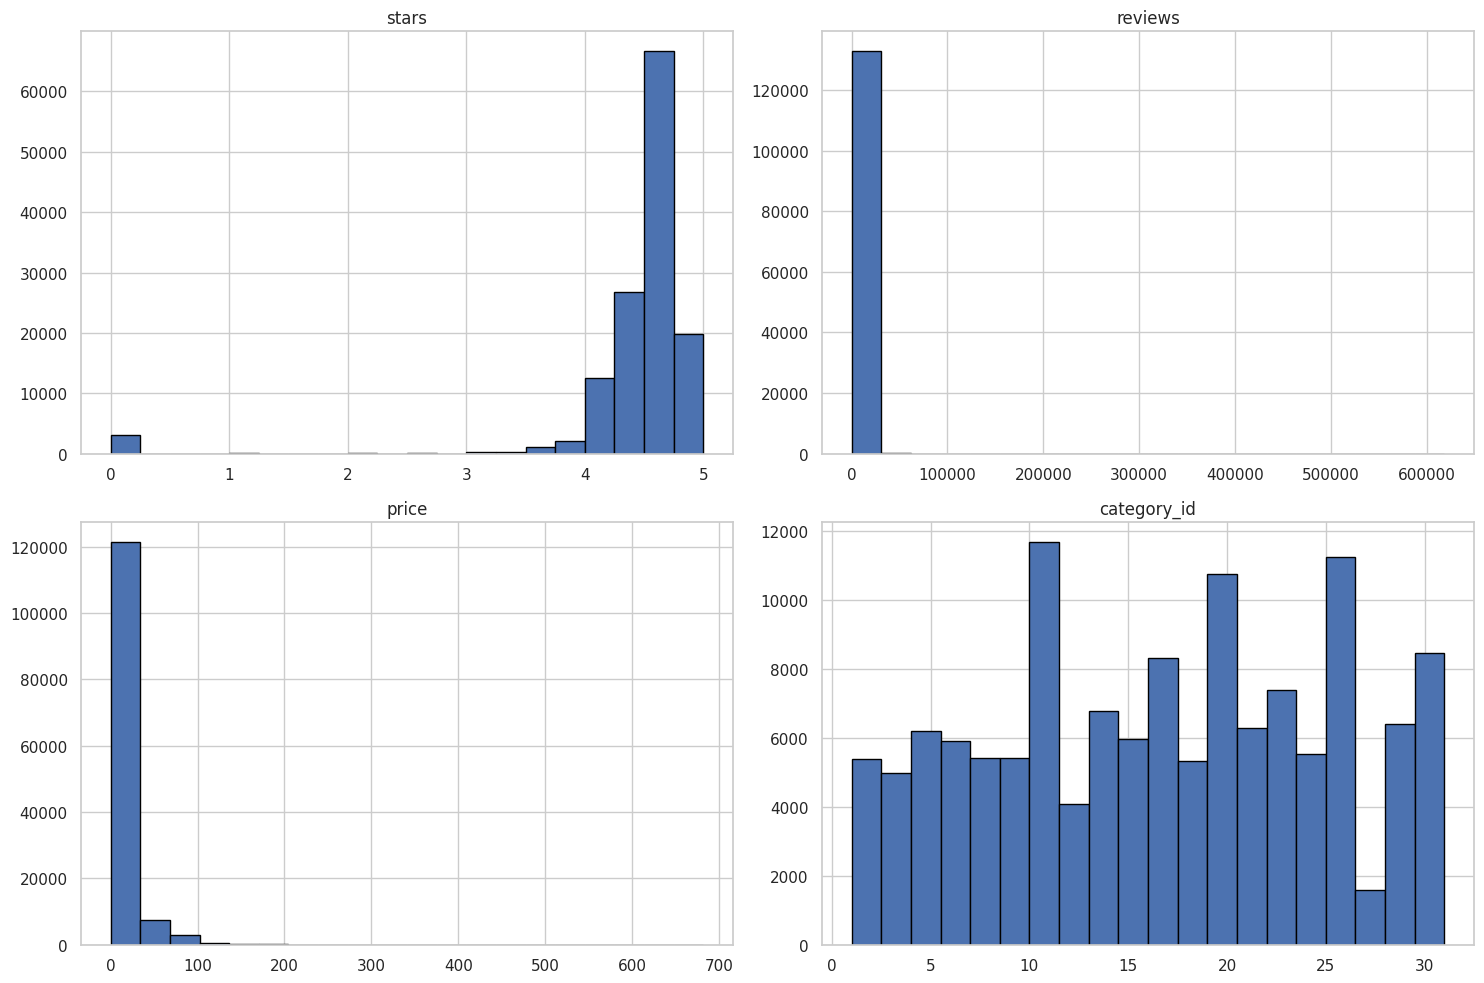

In [21]:
numerical_columns = df.select_dtypes(
    include='number'
).columns

df[numerical_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

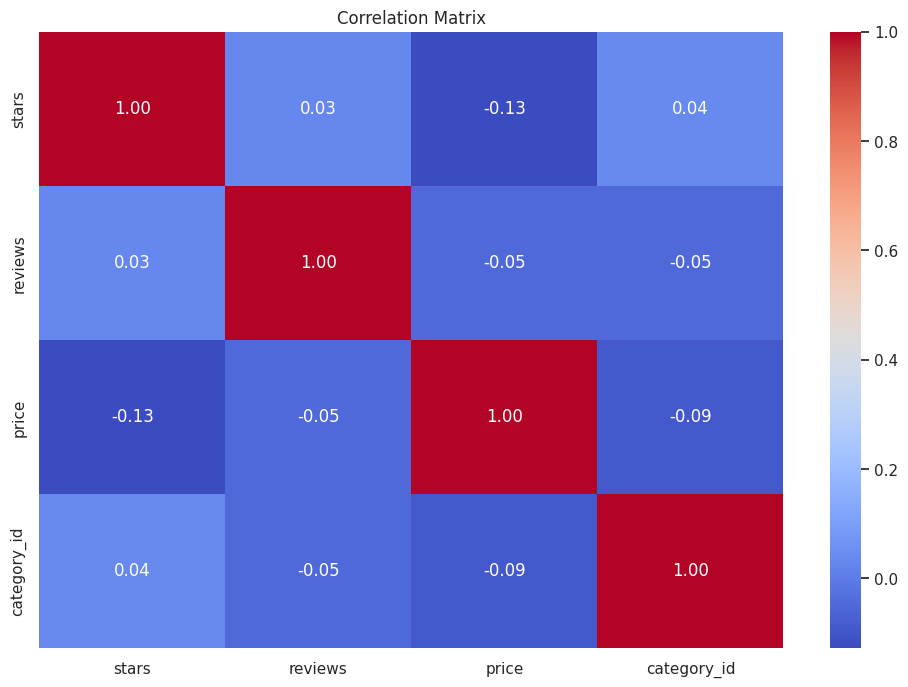

In [22]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.show()

In [ ]:
# Filter DataFrame for isBestSeller=True
df_true = df[df['isBestSeller'] == True]

# Get the counts for each category
category_counts = df_true['category_name'].value_counts()

# Sort the categories in descending order
sorted_categories = category_counts.index

# Create a bar plot
plt.figure(figsize=(12, 8))
sns.countplot(x='category_name', order=sorted_categories, data=df_true)
plt.title('Distribution of isBestSeller (True) by category_name (Sorted)')
plt.xlabel('Category Name')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.show()

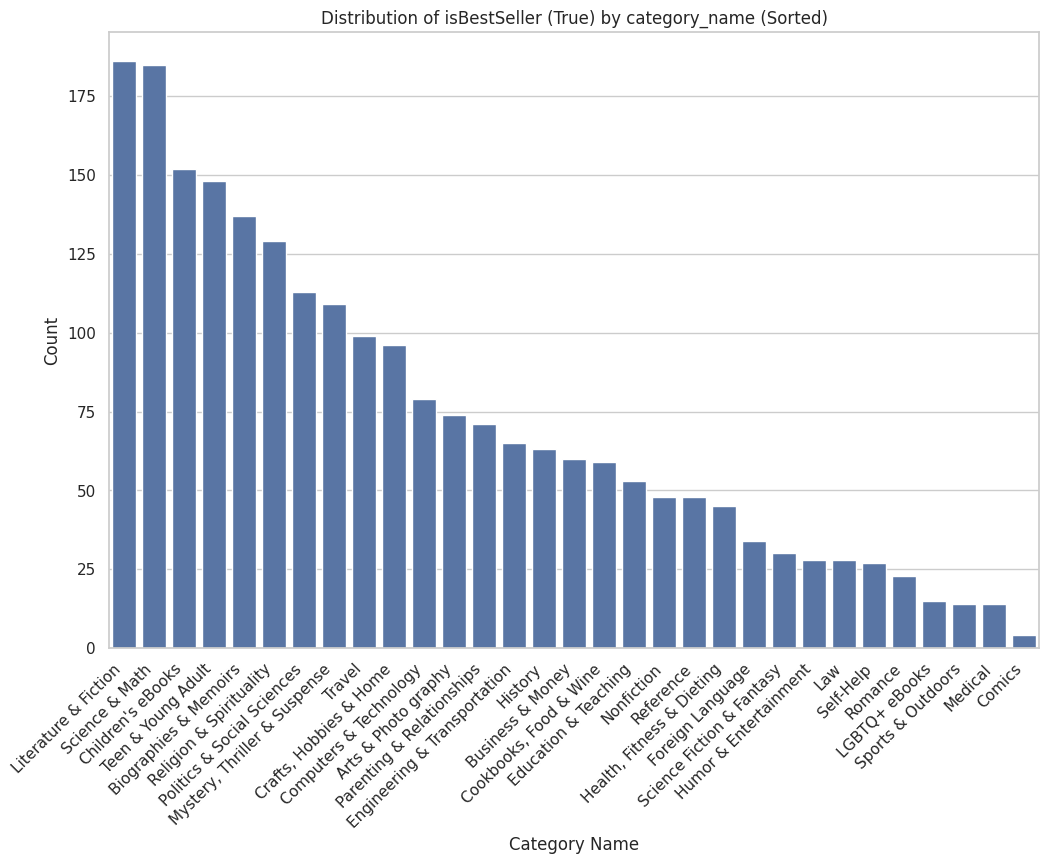

In [24]:
# Filter DataFrame for isBestSeller=True
df_true = df[df['isBestSeller'] == True]

# Get the counts for each category
category_counts = df_true['category_name'].value_counts()

# Sort the categories in descending order
sorted_categories = category_counts.index

# Create a bar plot
plt.figure(figsize=(12, 8))
sns.countplot(x='category_name', order=sorted_categories, data=df_true)
plt.title('Distribution of isBestSeller (True) by category_name (Sorted)')
plt.xlabel('Category Name')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.show()